## v6. Boundary losses of the whole 1993-2013 v3 production

Combines the four per-seed tables written by `v5.Meso_boundaries_bigrun_v3_losses.ipynb`
(one run per seed, `v2.Analysis_losses.sh`), 1534 releases of ~10061 wet particles, 185 days each.

Flags are those of v5: **left 29N** (reached `north_exit_lat` or deleted at the grid edge; excluded from every
other count), **froze** (|dlon|,|dlat| <= 1e-7 deg for >= 2 days, includes slow particles near the bed),
**stuck** (identical position for >= 2 days), **below the sea bed** (z > W bottom of its T cell), split by the
W bottom at the event into shelf (<= 200 m) and open ocean (> 200 m).

In [1]:
import pandas as pd, numpy as np
seeds = {11098723: '1993-1998', 45678: '1999-2004', 67891: '2005-2008', 78876: '2009-2013'}
shelf_max_depth = 200.0
parts = []
for s, yrs in seeds.items():
    d = pd.read_parquet(f'tracks_v3_{s}_boundary_losses.parquet')
    d['seed'] = s; d['period'] = yrs
    parts.append(d)
res = pd.concat(parts, ignore_index=True); del parts
print(f'{len(res)} particles, {res.release.nunique()} releases, {res.release.min().date()} .. {res.release.max().date()}')

15485167 particles, 1534 releases, 1993-01-06 .. 2013-12-28


## a) Counts per seed and for the whole period

In [2]:
def summary(d):
    ins = d[~d.left_domain]
    bb = ins[ins.below_bed]
    return pd.Series({
        'releases': d.release.nunique(),
        'particles': len(d),
        'left 29N': int(d.left_domain.sum()),
        'froze': int(ins.frozen.sum()),
        'stuck': int(ins.frozen_exact.sum()),
        'below bed shelf': int((bb.below_bed_wbottom <= shelf_max_depth).sum()),
        'below bed open ocean': int((bb.below_bed_wbottom > shelf_max_depth).sum()),
        'on land': int(ins.on_land.sum()),
        'deleted inside domain': int(ins.deleted.sum()),
    })

tab = res.groupby('period').apply(summary).T
tab['ALL 1993-2013'] = summary(res)
display(tab)
pct = tab.drop(index=['releases', 'particles']) / tab.loc['particles'] * 100
print('% of all particles of that period:')
display(pct.round(4))

/tmp/ipykernel_218199/1525909417.py:16: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tab = res.groupby('period').apply(summary).T


period,1993-1998,1999-2004,2005-2008,2009-2013,ALL 1993-2013
releases,438,439,292,365,1534
particles,4406718,4440924,2950660,3686865,15485167
left 29N,4907,3600,2447,5032,15986
froze,5220,5613,4013,5016,19862
stuck,279,332,206,295,1112
below bed shelf,7,8,9,5,29
below bed open ocean,0,0,0,0,0
on land,0,1,3,2,6
deleted inside domain,0,0,0,0,0


% of all particles of that period:


period,1993-1998,1999-2004,2005-2008,2009-2013,ALL 1993-2013
left 29N,0.1114,0.0811,0.0829,0.1365,0.1032
froze,0.1185,0.1264,0.1360,0.1361,0.1283
stuck,0.0063,0.0075,0.0070,0.0080,0.0072
below bed shelf,0.0002,0.0002,0.0003,0.0001,0.0002
below bed open ocean,0.0000,0.0000,0.0000,0.0000,0.0000
on land,0.0000,0.0000,0.0001,0.0001,0.0000
deleted inside domain,0.0000,0.0000,0.0000,0.0000,0.0000


## b) Where they froze / got stuck, and the below-bed particles

In [3]:
ins = res[~res.left_domain]
print('stuck (identical position >= 2 days), by location category:')
display(pd.crosstab(ins[ins.frozen_exact].frozen_cat, ins[ins.frozen_exact].period, margins=True))
print('froze (tolerance), by location category:')
display(pd.crosstab(ins[ins.frozen].frozen_cat, ins[ins.frozen].period, margins=True))
print('stuck duration [days]: median %.1f, max %.1f' % (ins[ins.frozen_exact].frozen_max_days.median(),
                                                        ins[ins.frozen_exact].frozen_max_days.max()))
bb = ins[ins.below_bed]
print(f'below the sea bed: {len(bb)} particles')
display(bb[['period', 'release', 'traj', 'below_bed_day', 'below_bed_cat', 'below_bed_lon', 'below_bed_lat',
            'below_bed_z', 'below_bed_wbottom', 'max_below_bed_m', 'days_below_bed', 'frozen_exact']])

stuck (identical position >= 2 days), by location category:


period,1993-1998,1999-2004,2005-2008,2009-2013,All
frozen_cat,,,,,
coast,227,266,165,244,902
other,1,0,2,0,3
shelf_bottom,51,66,39,51,207
All,279,332,206,295,1112


froze (tolerance), by location category:


period,1993-1998,1999-2004,2005-2008,2009-2013,All
frozen_cat,,,,,
coast,3586,3665,2656,3336,13243
other,192,244,168,211,815
shelf_bottom,1442,1704,1189,1469,5804
All,5220,5613,4013,5016,19862


stuck duration [days]: median 108.1, max 183.8
below the sea bed: 29 particles


,period,release,traj,below_bed_day,below_bed_cat,below_bed_lon,below_bed_lat,below_bed_z,below_bed_wbottom,max_below_bed_m,days_below_bed,frozen_exact
94933,1993-1998,1993-02-20,7106,123.75,coast,-65.612808,18.226260,10.463035,10.463024,0.000010,61.25,True
221312,1993-1998,1993-04-21,16350,6.00,shelf_bottom,-49.875000,1.791375,11.994968,8.729996,3.264972,179.00,True
1679936,1993-1998,1995-04-12,15991,58.00,coast,-50.208332,1.853103,8.730007,8.729996,0.000011,127.00,True
2943922,1993-1998,1997-01-01,9926,57.25,shelf_bottom,-59.458333,9.086669,7.398182,7.167652,0.230530,127.75,True
2979921,1993-1998,1997-01-21,2988,60.25,shelf_bottom,-60.791668,11.055747,25.318737,23.334993,1.983744,124.75,True
3281551,1993-1998,1997-06-20,2677,2.75,shelf_bottom,-49.409534,0.624988,8.730001,8.729996,0.000006,182.25,True
3293291,1993-1998,1997-06-25,5414,5.75,coast,-50.208332,1.950527,14.599936,14.599932,0.000005,179.25,True
5589583,1999-2004,2000-08-03,15252,1.00,shelf_bottom,-49.395460,0.624988,8.730043,8.729996,0.000047,184.00,True
5632846,1999-2004,2000-08-28,3348,13.50,shelf_bottom,-50.082437,2.041235,7.167670,7.167652,0.000018,171.50,True
6591845,1999-2004,2001-12-16,111,28.25,shelf_bottom,-50.291668,2.707325,8.661254,7.167652,1.493602,156.75,True


## c) Per-release rates over the 21 years

/tmp/ipykernel_218199/1049688684.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per_rel = res.groupby('release').apply(lambda d: pd.Series({


,left 29N %,froze %,stuck %
count,1534.0000,1534.0000,1534.0000
mean,0.1033,0.1284,0.0072
std,0.2069,0.0812,0.0090
min,0.0000,0.0000,0.0000
25%,0.0000,0.0692,0.0000
50%,0.0198,0.1090,0.0000
75%,0.0989,0.1790,0.0099
max,1.8117,0.4274,0.0495


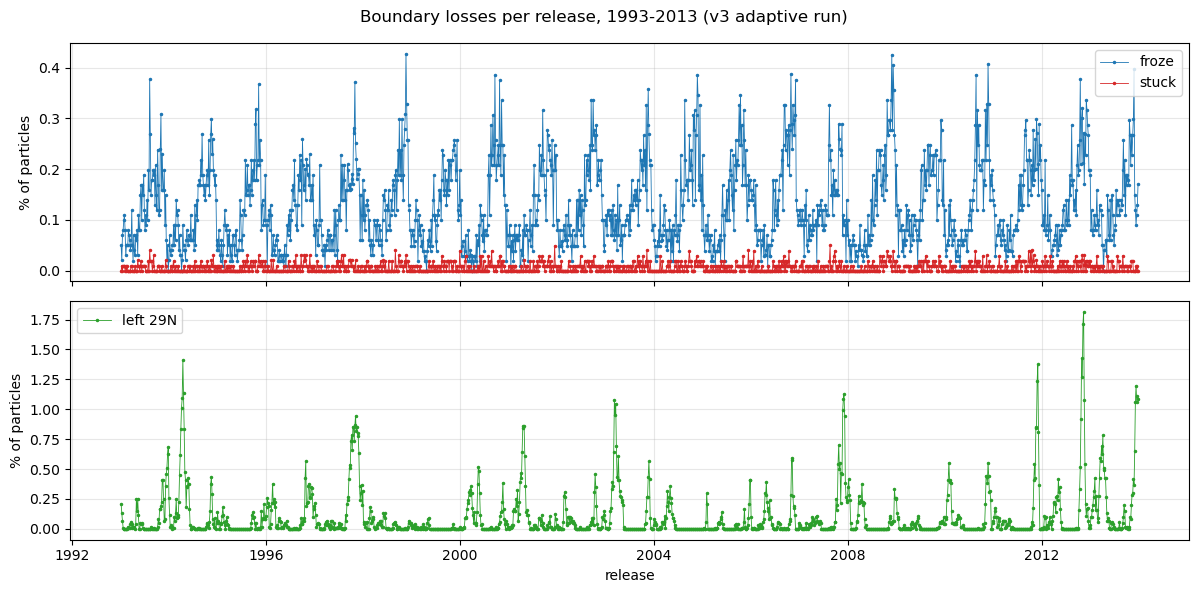

In [4]:
per_rel = res.groupby('release').apply(lambda d: pd.Series({
    'left 29N %': d.left_domain.mean() * 100,
    'froze %': d[~d.left_domain].frozen.mean() * 100,
    'stuck %': d[~d.left_domain].frozen_exact.mean() * 100}))
display(per_rel.describe().round(4))
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(per_rel.index, per_rel['froze %'], '.-', ms=3, lw=0.6, color='tab:blue', label='froze')
ax[0].plot(per_rel.index, per_rel['stuck %'], '.-', ms=3, lw=0.6, color='tab:red', label='stuck')
ax[0].set_ylabel('% of particles'); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(per_rel.index, per_rel['left 29N %'], '.-', ms=3, lw=0.6, color='tab:green', label='left 29N')
ax[1].set_ylabel('% of particles'); ax[1].set_xlabel('release'); ax[1].legend(); ax[1].grid(alpha=0.3)
for s, yrs in seeds.items():
    pass
plt.suptitle('Boundary losses per release, 1993-2013 (v3 adaptive run)')
plt.tight_layout(); plt.show()

## d) Where the losses happen

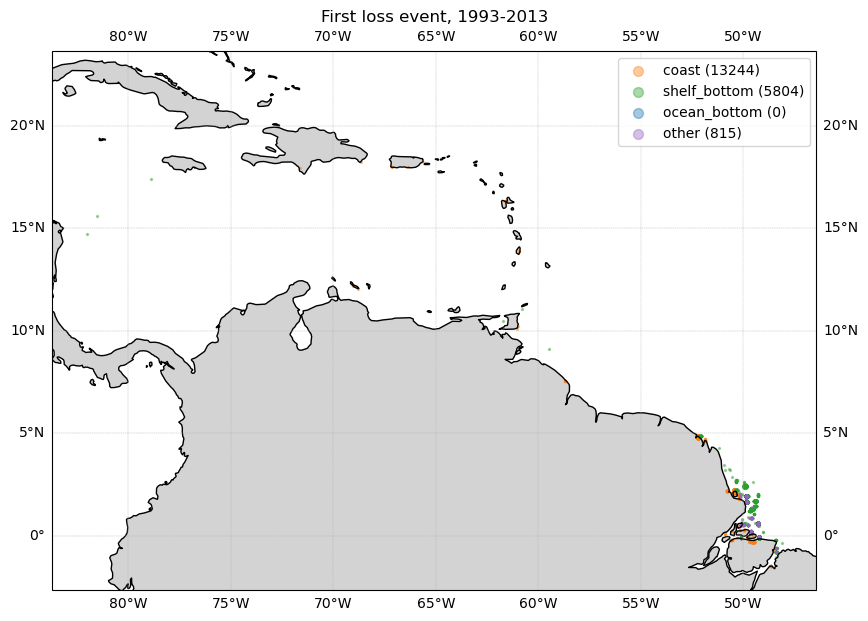

In [5]:
import cartopy.crs as ccrs, cartopy.feature as cfeature
L = res[res.lost & res.lost_lon.notna()]
colors = {'coast': 'tab:orange', 'shelf_bottom': 'tab:green', 'ocean_bottom': 'tab:blue', 'other': 'tab:purple'}
fig = plt.figure(figsize=(11, 7))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='lightgray'); ax.coastlines(resolution='50m')
ax.gridlines(draw_labels=True, linestyle='--', linewidth=0.3)
for c, col in colors.items():
    s_ = L[L.lost_cat == c]
    ax.scatter(s_.lost_lon, s_.lost_lat, s=2, color=col, alpha=0.4, transform=ccrs.PlateCarree(), label=f'{c} ({len(s_)})')
ax.legend(loc='upper right', markerscale=5)
plt.title('First loss event, 1993-2013'); plt.show()

## Conclusions (1993-2013, 1534 releases, 15 485 167 particles, 185 days each)

* **Left at 29 N**: 15 986 = 0.103 % (0.081-0.137 % per period), excluded from everything below.
* **Really stuck** (identical lon/lat >= 2 days): **1112 = 0.0072 %**, stable over the 21 years (0.0063-0.0080 % per period).
  Coast 902, shelf bottom 207, other 3; median stuck duration 108 days. These sit in dead-end pockets of the
  deepest wet level where the velocity field converges (a data problem, not the integrator; see v4/v5).
* **Froze with the 1e-7 deg tolerance** (mostly slow near the bed, moving again later): 19 862 = 0.128 %,
  coast 13 243, shelf bottom 5804, other 815.
* **Below the sea bed: 29 particles = 0.0002 %, all on the shelf, none in the open ocean.**
  18 of them are within 1e-4 m of the W bottom (round-off); the deepest is 5.0 m below an 8.7 m bed
  (2012-05-02, 49.875 W). 28 of the 29 are also stuck.
* **On land: 6 (0.00004 %). Above surface / deleted inside the domain: 0.**
* Per release: froze 0-0.43 % (median 0.11 %), stuck 0-0.05 % (median 0), left 29 N 0-1.81 % (median 0.02 %).
* The rates do not drift over the 21 years, so the adaptive sub-stepping behaves the same in every period and
  with every seed.